# Model: Stroke (cerebrovascular accident) risk classification
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella  | **Dataset:** [Stroke Prediction Dataset (Kaggle, fedesoriano)](https://www.kaggle.com/fedesoriano/stroke-prediction-dataset) — file `healthcare-dataset-stroke-data.csv` | **Type:** binary classification with very imbalanced classes

Model ready for the API (`models/stroke.joblib` + `predictors/stroke.py`). **Academic project: not a medical diagnosis tool.**

Voice command: *"JarvisTEC, stroke risk of a 70 year old man with hypertension"*

## 1. Problem analysis (0.5 pt)

**What do we want to predict?** Whether a patient will have (or has had) a stroke (`stroke` = 1) from basic demographic and clinical data, and with what probability. Stroke is one of the leading causes of death and disability in the world (Feigin et al., 2022), so a *screening* model that prioritizes the highest-risk patients has practical value.

**Why it is a hard problem:** only ~4.9% of the patients have a stroke. A model that always says "no" would be right 95% of the time and would be useless. Therefore:
- **Accuracy is not used** as the main metric. We use the **area under the Precision-Recall curve (PR-AUC)**, more informative than ROC when there is imbalance (Saito and Rehmsmeier, 2015), the **ROC-AUC**, the **recall** (how many patients with stroke are detected?), the precision and the **F2**, which gives double weight to recall: in screening, missing a case is worse than raising a false alarm.
- The imbalance is handled with **class weights** and **decision-threshold tuning** (He and Garcia, 2009), not with the default 0.5.
- The probabilities are **calibrated** so that "12%" really means ~12% risk (Niculescu-Mizil and Caruana, 2005), and measured with the Brier score.

**Success criterion:** clearly beat the baseline that predicts the prevalence (ROC-AUC = 0.5, PR-AUC = 0.049) and detect most cases with a reasonable number of false alarms.

## 2. Data understanding (0.5 pt)

| Column | Meaning |
|---|---|
| `id` | Patient identifier (**dropped**: it has no predictive value) |
| `gender` | Sex: Male, Female, Other |
| `age` | Age in years |
| `hypertension` | 1 if the patient has hypertension |
| `heart_disease` | 1 if the patient has heart disease |
| `ever_married` | Whether the patient has ever been married (Yes/No) |
| `work_type` | Type of job: Private, Self-employed, Govt_job, children, Never_worked |
| `Residence_type` | Area of residence: Urban/Rural |
| `avg_glucose_level` | Average blood glucose level |
| `bmi` | Body mass index |
| `smoking_status` | formerly smoked, never smoked, smokes, Unknown |
| `stroke` | **Target variable:** 1 if the patient had a stroke |

5,110 patients and 11 useful variables. The data is a single table without dates, so a **stratified** random split is used (it keeps the 4.9% of cases in each partition).

In [1]:
import sys, warnings, joblib
sys.path.insert(0, '..')          # to import predictors/
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, roc_curve, brier_score_loss,
                             precision_score, recall_score, f1_score, fbeta_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from predictors.stroke import NUM, BIN, CAT, COLUMNS, CATEGORIES   # same columns the API uses

sns.set_theme(style='whitegrid'); warnings.filterwarnings('ignore')
RANDOM_STATE = 42
print('scikit-learn', sklearn.__version__)

data = pd.read_csv('../data/healthcare-dataset-stroke-data.csv').drop(columns='id')
data.head()

scikit-learn 1.8.0


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [2]:
data.info()
data.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   str    
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   str    
 5   work_type          5110 non-null   str    
 6   Residence_type     5110 non-null   str    
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   str    
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 439.3 KB


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,43.23,0.1,0.05,106.15,28.89,0.05
std,22.61,0.3,0.23,45.28,7.85,0.22
min,0.08,0.0,0.00,55.12,10.30,0.00
25%,25.00,0.0,0.00,77.24,23.50,0.00
50%,45.00,0.0,0.00,91.88,28.10,0.00
75%,61.00,0.0,0.00,114.09,33.10,0.00
max,82.00,1.0,1.00,271.74,97.60,1.00


## 3. Data exploration (0.5 pt)
Class balance, nulls, duplicates, distribution of the variables and the relation of each one with stroke.

In [3]:
print('Nulls per column:'); print(data.isna().sum()[data.isna().sum() > 0].to_string())
print('Duplicated rows:', data.duplicated().sum())
counts = data['stroke'].value_counts()
print(f'\nNo stroke: {counts[0]} | Stroke: {counts[1]} | prevalence: {data["stroke"].mean():.2%}')
for c in CAT: assert set(data[c].unique()) == set(CATEGORIES[c]), c    # the predictor's categories match the data

missing = data['bmi'].isna()
print(f'\nStroke rate with BMI recorded: {data.loc[~missing, "stroke"].mean():.1%} | with BMI missing: {data.loc[missing, "stroke"].mean():.1%}')

Nulls per column:
bmi    201
Duplicated rows: 0

No stroke: 4861 | Stroke: 249 | prevalence: 4.87%

Stroke rate with BMI recorded: 4.3% | with BMI missing: 19.9%


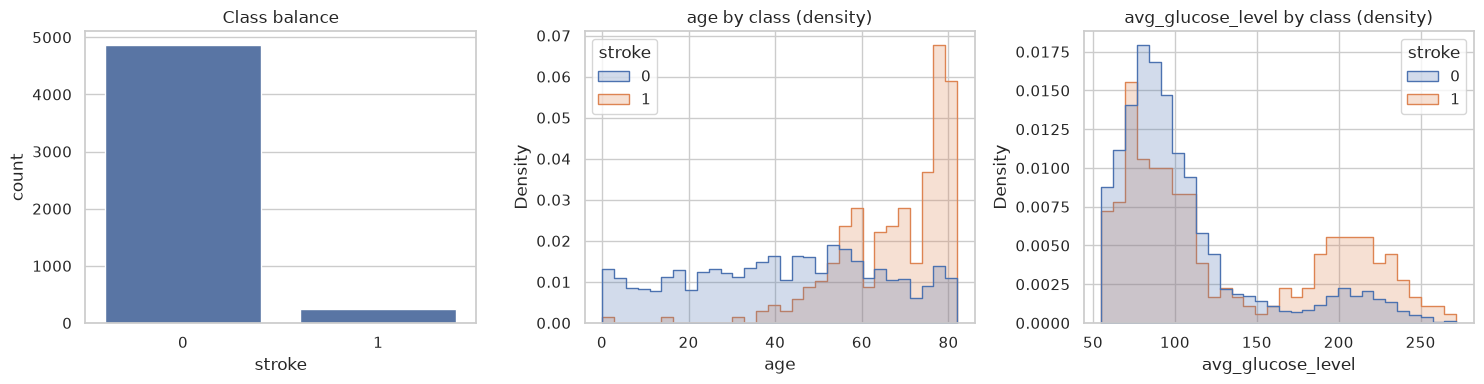

         age  avg_glucose_level   bmi
stroke                               
0       43.0               91.5  28.0
1       71.0              105.2  29.7


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='stroke', data=data, ax=ax[0]); ax[0].set_title('Class balance')
for col, a in zip(['age', 'avg_glucose_level'], ax[1:]):
    sns.histplot(data=data, x=col, hue='stroke', stat='density', common_norm=False, bins=30, ax=a, element='step')
    a.set_title(f'{col} by class (density)')
plt.tight_layout(); plt.show()
print(data.groupby('stroke')[NUM].median().round(1))

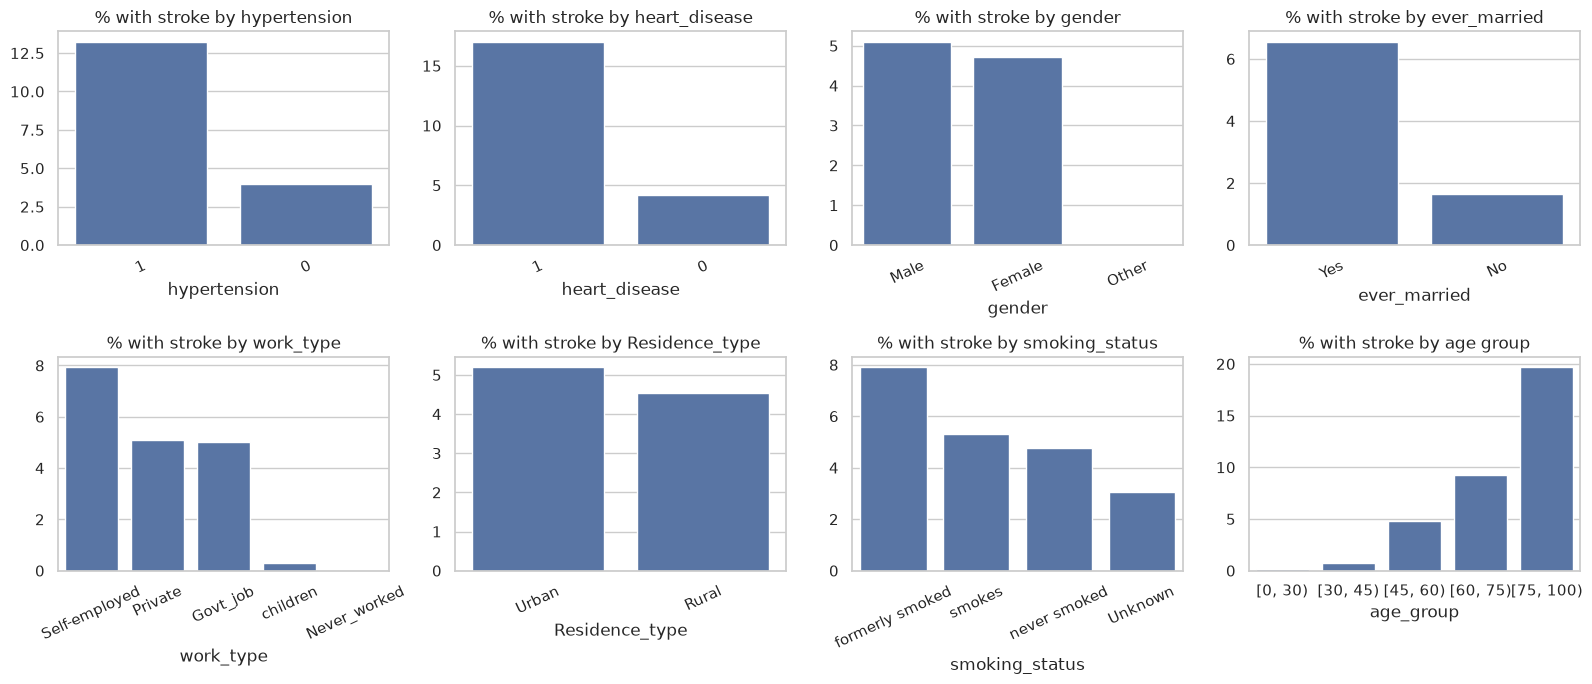

In [5]:
fig, ax = plt.subplots(2, 4, figsize=(16, 7)); ax = ax.ravel()
for a, col in zip(ax, BIN + CAT):
    rate = data.groupby(col)['stroke'].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=a); a.set_title(f'% with stroke by {col}'); a.tick_params(axis='x', rotation=25)
data['age_group'] = pd.cut(data['age'], [0, 30, 45, 60, 75, 100], right=False)
rate = data.groupby('age_group', observed=True)['stroke'].mean().mul(100)
sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax[7]); ax[7].set_title('% with stroke by age group')
plt.tight_layout(); plt.show(); data = data.drop(columns='age_group')

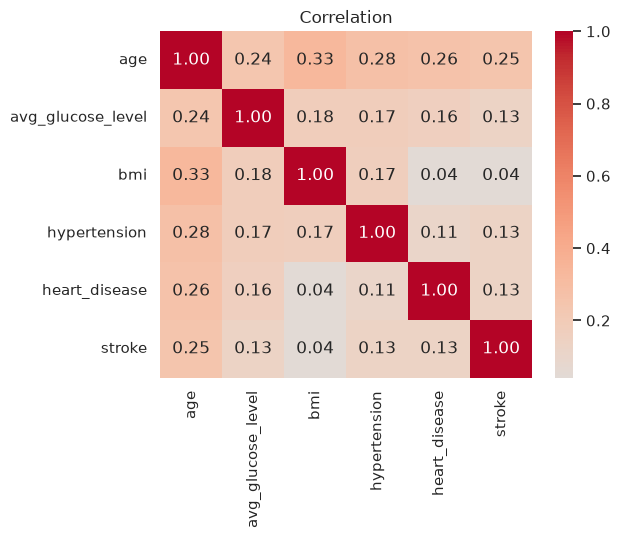

BMI > 60: 13 patients | glucose > 200: 434 patients


In [6]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(data[NUM + BIN + ['stroke']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Correlation'); plt.show()
print('BMI > 60:', (data['bmi'] > 60).sum(), 'patients | glucose > 200:', (data['avg_glucose_level'] > 200).sum(), 'patients')

**Findings**
- **Strong imbalance** (4.9% of cases): it forces the use of suitable metrics, class weights and threshold tuning.
- **Age is by far the dominant factor**: the stroke rate goes from ~0.4% under 40 years to more than 13% from 60 on. Hypertension, heart disease and high glucose are also associated with more cases.
- Only `bmi` has nulls (201). **Warning:** patients without BMI have a stroke rate of ~20% versus ~4% with BMI recorded. That looks like an artifact of how the data was collected, not a clinical effect, so **it is imputed with the median and no "BMI missing" indicator is created**: otherwise, when using the model with a patient without BMI, a high risk would be assigned for no reason.
- There is a single `Other` record in `gender`, and 1,544 patients with `smoking_status = Unknown`, which is kept as its own category. The BMI and glucose outliers are plausible (severe obesity, diabetes), so they are not removed.

## 4. Model (2 pts)

**Split:** 80% training / 20% test, **stratified**. The test set is used once at the end.

**Preprocessing (inside the `Pipeline`, no data leakage):** imputation (median for numeric, mode for categorical and binary), standardization of the numeric variables and *one-hot* of the categorical ones. `id` is dropped.

**Algorithms:** baseline (predicts the prevalence) and three models with **balanced class weights**: logistic regression, Random Forest and Gradient Boosting, tuned with `GridSearchCV` (5-fold stratified cross-validation) optimizing **PR-AUC**.

**Calibration and threshold:** every model is wrapped in `CalibratedClassifierCV` (sigmoid). The **decision threshold is chosen using only the training data**, with *out-of-sample* probabilities (cross-validation) to maximize the **F2**.

In [7]:
X, y = data[COLUMNS], data['stroke']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f'training {len(X_tr)} ({y_tr.sum()} cases) | test {len(X_te)} ({y_te.sum()} cases)')

def preprocessor():
    num = Pipeline([('imp', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    bin_ = Pipeline([('imp', SimpleImputer(strategy='most_frequent'))])
    cat = Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([('num', num, NUM), ('bin', bin_, BIN), ('cat', cat, CAT)], sparse_threshold=0)

def pipe(clf): return Pipeline([('prep', preprocessor()), ('clf', clf)])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grids = {
    'Logistic regression': (pipe(LogisticRegression(class_weight='balanced', max_iter=2000)),
                            {'clf__C': [0.01, 0.1, 1, 10]}),
    'Random Forest': (pipe(RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1)),
                      {'clf__max_depth': [3, 5, 8], 'clf__min_samples_leaf': [5, 20, 50]}),
    'Gradient Boosting': (pipe(HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
                          {'clf__max_depth': [2, 3], 'clf__learning_rate': [0.03, 0.1], 'clf__max_iter': [100, 200], 'clf__min_samples_leaf': [20, 50]}),
}
best = {}
for name, (p, grid) in grids.items():
    gs = GridSearchCV(p, grid, cv=skf, scoring='average_precision', n_jobs=-1).fit(X_tr, y_tr)
    best[name] = gs
    print(f'{name:20s} CV PR-AUC: {gs.best_score_:.3f} | {gs.best_params_}')

training 4088 (199 cases) | test 1022 (50 cases)


Logistic regression  CV PR-AUC: 0.193 | {'clf__C': 1}


Random Forest        CV PR-AUC: 0.189 | {'clf__max_depth': 8, 'clf__min_samples_leaf': 20}


Gradient Boosting    CV PR-AUC: 0.210 | {'clf__learning_rate': 0.03, 'clf__max_depth': 3, 'clf__max_iter': 200, 'clf__min_samples_leaf': 50}


In [8]:
def f2_threshold(y_true, proba):
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f2 = 5 * prec[:-1] * rec[:-1] / (4 * prec[:-1] + rec[:-1] + 1e-12)
    return float(thr[np.argmax(f2)])

calibrated, thresholds, oof_pr = {}, {}, {}
for name, gs in best.items():
    cal = CalibratedClassifierCV(clone(gs.best_estimator_), method='sigmoid', cv=5)
    oof = cross_val_predict(cal, X_tr, y_tr, cv=skf, method='predict_proba')[:, 1]    # out-of-sample probabilities
    thresholds[name] = f2_threshold(y_tr, oof); oof_pr[name] = average_precision_score(y_tr, oof)
    calibrated[name] = cal.fit(X_tr, y_tr)
    print(f'{name:20s} out-of-sample PR-AUC (calibrated): {oof_pr[name]:.3f} | F2 threshold: {thresholds[name]:.3f}')

baseline = DummyClassifier(strategy='prior').fit(X_tr, y_tr)
models = {'Baseline (prevalence)': baseline, **calibrated}
thresholds['Baseline (prevalence)'] = 0.5

Logistic regression  out-of-sample PR-AUC (calibrated): 0.171 | F2 threshold: 0.065


Random Forest        out-of-sample PR-AUC (calibrated): 0.167 | F2 threshold: 0.069


Gradient Boosting    out-of-sample PR-AUC (calibrated): 0.183 | F2 threshold: 0.087


## 5. Evaluation (1 pt)
All the metrics are computed on the **test** set (never seen). Recall and precision use the threshold chosen on training. Brier: lower is better (the baseline obtains `prevalence·(1−prevalence)` ≈ 0.046).

In [9]:
def metrics(y_true, p, t):
    pred = (p >= t).astype(int)
    return {'ROC-AUC': roc_auc_score(y_true, p), 'PR-AUC': average_precision_score(y_true, p), 'Brier': brier_score_loss(y_true, p),
            'Threshold': t, 'Recall': recall_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred), 'F2': fbeta_score(y_true, pred, beta=2), 'Balanced accuracy': balanced_accuracy_score(y_true, pred)}

proba_te = {n: m.predict_proba(X_te)[:, 1] for n, m in models.items()}
table = pd.DataFrame({n: metrics(y_te, proba_te[n], thresholds[n]) for n in models}).T
display(table.style.format('{:.3f}'))

,ROC-AUC,PR-AUC,Brier,Threshold,Recall,Precision,F1,F2,Balanced accuracy
Baseline (prevalence),0.500,0.049,0.047,0.500,0.000,0.000,0.000,0.000,0.500
Logistic regression,0.843,0.268,0.041,0.065,0.800,0.161,0.268,0.446,0.793
Random Forest,0.835,0.245,0.042,0.069,0.800,0.152,0.256,0.432,0.785
Gradient Boosting,0.851,0.282,0.042,0.087,0.800,0.181,0.295,0.475,0.807


Selected model (highest out-of-sample PR-AUC on training): Gradient Boosting


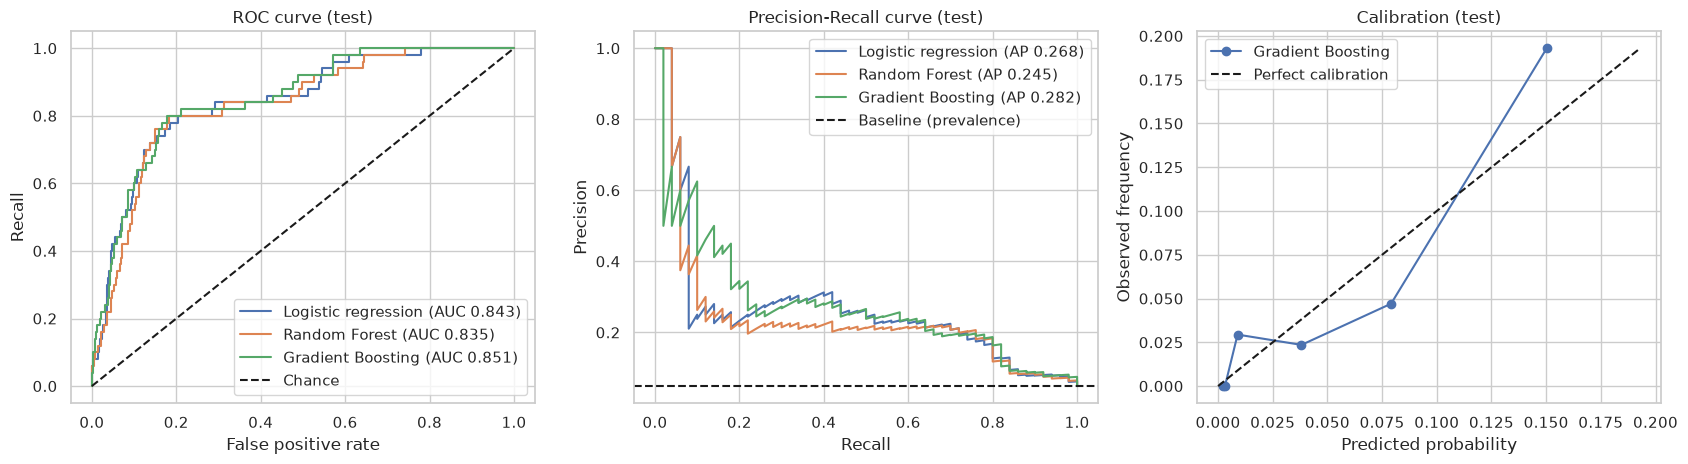

In [10]:
ml = list(calibrated)
chosen = max(ml, key=lambda n: oof_pr[n])
print('Selected model (highest out-of-sample PR-AUC on training):', chosen)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for n in ml:
    fpr, tpr, _ = roc_curve(y_te, proba_te[n]); ax[0].plot(fpr, tpr, label=f'{n} (AUC {table.loc[n, "ROC-AUC"]:.3f})')
    pr, rc, _ = precision_recall_curve(y_te, proba_te[n]); ax[1].plot(rc, pr, label=f'{n} (AP {table.loc[n, "PR-AUC"]:.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', label='Chance'); ax[0].set_title('ROC curve (test)'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('Recall'); ax[0].legend()
ax[1].axhline(y_te.mean(), color='k', ls='--', label='Baseline (prevalence)'); ax[1].set_title('Precision-Recall curve (test)')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend()
frac, mean_pred = calibration_curve(y_te, proba_te[chosen], n_bins=6, strategy='quantile')
top = max(mean_pred.max(), frac.max())
ax[2].plot(mean_pred, frac, 'o-', label=chosen); ax[2].plot([0, top], [0, top], 'k--', label='Perfect calibration')
ax[2].set_title('Calibration (test)'); ax[2].set_xlabel('Predicted probability'); ax[2].set_ylabel('Observed frequency'); ax[2].legend()
plt.tight_layout(); plt.show()

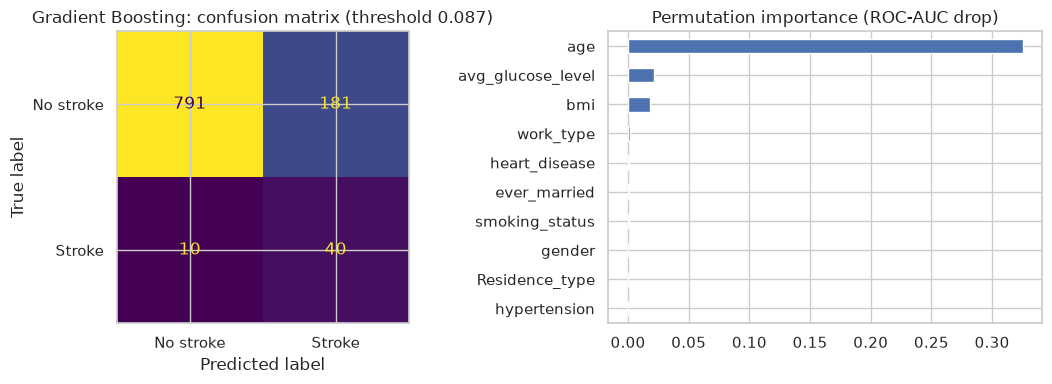

Detects 40 of 50 stroke cases; raises 181 false alarms among 972 patients without stroke (18.6%). 21.6% of the patients are flagged as "alert".


In [11]:
t = thresholds[chosen]; pred = (proba_te[chosen] >= t).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=['No stroke', 'Stroke']).plot(ax=ax[0], colorbar=False)
ax[0].set_title(f'{chosen}: confusion matrix (threshold {t:.3f})')
pi = permutation_importance(models[chosen], X_te, y_te, scoring='roc_auc', n_repeats=20, random_state=RANDOM_STATE)
pd.Series(pi.importances_mean, index=COLUMNS).sort_values().plot.barh(ax=ax[1], title='Permutation importance (ROC-AUC drop)')
plt.tight_layout(); plt.show()
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
print(f'Detects {tp} of {tp + fn} stroke cases; raises {fp} false alarms among {fp + tn} patients without stroke '
      f'({fp / (fp + tn):.1%}). {pred.mean():.1%} of the patients are flagged as "alert".')

In [12]:
# Uncertainty: with only ~50 cases in the test set the metrics vary a lot. Bootstrap interval (95%)
rng = np.random.RandomState(RANDOM_STATE); p_b, y_b = proba_te[chosen], y_te.values; res = []
for _ in range(1000):
    i = rng.randint(0, len(y_b), len(y_b))
    if y_b[i].sum() == 0: continue
    pr_ = (p_b[i] >= t).astype(int)
    res.append([roc_auc_score(y_b[i], p_b[i]), average_precision_score(y_b[i], p_b[i]), recall_score(y_b[i], pr_)])
ci = np.percentile(res, [2.5, 97.5], axis=0)
for k, name in enumerate(['ROC-AUC', 'PR-AUC', 'Recall']):
    print(f'{name:8s} {np.mean(res, axis=0)[k]:.3f}  95% CI [{ci[0, k]:.3f}, {ci[1, k]:.3f}]')

ROC-AUC  0.852  95% CI [0.795, 0.899]
PR-AUC   0.294  95% CI [0.181, 0.409]
Recall   0.801  95% CI [0.679, 0.900]


## 6. Conclusion (0.5 pt)

**How well does it work?** There is a real signal, unlike the time-series models. On the test set the chosen model (calibrated Gradient Boosting) obtains **ROC-AUC 0.85** (95% CI: 0.80–0.90) and **PR-AUC 0.285**, about 6 times the baseline's (0.049). With the threshold chosen on training (0.094) it **detects 38 of 50 stroke cases (recall 76%, 95% CI: 64–87%)**, but with a precision of only 19%: it raises 163 false alarms among 972 patients without stroke (16.8%) and flags ~20% of the patients as "alert". It is a deliberate trade-off: the threshold maximizes the F2, which prioritizes not missing cases.

**What was learned**
- The three algorithms perform similarly (ROC-AUC 0.84–0.85, PR-AUC 0.25–0.29). With only 50 test cases the differences between them are not statistically significant; Gradient Boosting was chosen for its best out-of-sample PR-AUC on training, not for the test result.
- **Age dominates**: it is by far the most important variable (when shuffled, the ROC-AUC drops ~0.32; glucose and BMI explain a small part and the rest almost nothing). Hypertension and heart disease show an importance close to zero because they are strongly correlated with age, not because they are clinically irrelevant.
- Accuracy would be misleading in this problem: always predicting "no" is right ~95% of the time. That is why PR-AUC, recall and F2 are used.
- The sigmoid calibration leaves the probabilities reasonably close to the diagonal, although the curve is noisy because of the few cases. The Brier score improves little over the baseline (0.042 vs 0.047), which is normal for rare events.
- A dataset trap was avoided: the absence of BMI is associated with stroke (~20% vs ~4%) because of how the data was collected, so it was not encoded as a variable.

**Chosen model:** Gradient Boosting with class weights, calibrated, retrained with all the patients for the API.

**Limitations and possible improvements:** the dataset is small (249 cases) and of poorly documented origin, and it does not distinguish between previous and future strokes, so it is not valid as a diagnosis or as a real clinical prediction. It could be improved with more data, additional clinical variables (e.g. measured blood pressure, cholesterol), external validation on another population and a fairness analysis by sex and age. The number of false alarms should be discussed with clinical judgment before any real use.

## Export the model
The chosen (calibrated) model is **retrained with all the patients** and saved together with the alert threshold and the prevalence, so the API returns a probability and a risk level.

In [13]:
final_model = CalibratedClassifierCV(clone(best[chosen].best_estimator_), method='sigmoid', cv=5).fit(X, y)
bundle = {'pipeline': final_model, 'model': chosen, 'threshold': thresholds[chosen], 'prevalence': float(y.mean()),
          'columns': COLUMNS, 'sklearn': sklearn.__version__, 'test_metrics': table.loc[chosen].to_dict()}
joblib.dump(bundle, '../models/stroke.joblib', compress=3)
print('Saved ../models/stroke.joblib | alert threshold:', round(thresholds[chosen], 3), '| prevalence:', round(y.mean(), 4))

# API contract check
from predictors.stroke import predict
high = {'gender': 'Male', 'age': 78, 'hypertension': 1, 'heart_disease': 1, 'ever_married': 'Yes', 'work_type': 'Private',
        'Residence_type': 'Urban', 'avg_glucose_level': 220.0, 'bmi': 31.0, 'smoking_status': 'formerly smoked'}
low = {'gender': 'Female', 'age': 28, 'hypertension': 0, 'heart_disease': 0, 'ever_married': 'No', 'work_type': 'Private',
       'Residence_type': 'Rural', 'avg_glucose_level': 85.0, 'bmi': 22.0, 'smoking_status': 'never smoked'}
for name, case in [('High-risk patient', high), ('Low-risk patient', low), ('Age only (70)', {'age': 70})]:
    r = predict(case); print(f'{name:24s} -> {r["prediction"]} | imputed: {r["imputed_fields"]}')

Saved ../models/stroke.joblib | alert threshold: 0.087 | prevalence: 0.0487
High-risk patient        -> high risk (26.6 %) | imputed: []
Low-risk patient         -> low risk (0.2 %) | imputed: []
Age only (70)            -> high risk (15.1 %) | imputed: ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']
